# Predicting 30-day hospital readmission

Can discharge-time data flag the diabetic inpatients most likely to return within 30 days? This notebook walks through the analysis implemented in `modeling.py` on the UCI Diabetes 130-US Hospitals data (101,766 encounters, 1999 to 2008).

Design: encounters ending in death or hospice are excluded, the data are split 60/20/20 **by patient**, a logistic regression and a gradient-boosted model are tuned and compared on the validation patients only, and the test patients are scored once.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from modeling import run_analysis

pd.set_option("display.precision", 3)
summary = run_analysis(Path("data") / "diabetic_data.csv.gz")
pd.Series({**summary["data"], **summary["split"]})

source_rows                                                             101766
rows_after_eligibility                                                   99343
patients                                                                 69990
share_of_patients_with_repeat_encounters                                 0.233
share_of_encounters_from_repeat_patients                                  0.46
target_prevalence                                                        0.114
prediction_timestamp                        end of index encounter (discharge)
train_rows                                                               59565
validation_rows                                                          19917
test_rows                                                                19861
train_patients                                                           41994
validation_patients                                                      13998
test_patients                                       

## Model selection (validation patients only)

Each candidate is fit on the training patients and scored on the validation patients. The model with the highest validation ROC-AUC is selected before the test set is touched.

In [2]:
pd.read_csv("metrics/model_selection.csv")

,model,params,roc_auc,pr_auc,brier,log_loss
0,logistic_regression,"{""C"": 0.01}",0.660,0.212,0.097,0.337
1,logistic_regression,"{""C"": 0.1}",0.661,0.215,0.097,0.336
2,logistic_regression,"{""C"": 1.0}",0.661,0.214,0.097,0.336
3,gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 300, ""max_...",0.672,0.230,0.096,0.333
4,gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 500, ""max_...",0.671,0.228,0.096,0.334
5,gradient_boosting,"{""learning_rate"": 0.03, ""max_iter"": 800, ""max_...",0.673,0.232,0.096,0.333
6,gradient_boosting,"{""learning_rate"": 0.03, ""max_iter"": 400, ""max_...",0.675,0.234,0.095,0.332


## Held-out test performance

ROC-AUC and PR-AUC measure ranking; Brier score and log loss measure probability accuracy. Intervals come from a patient-cluster bootstrap (whole patients resampled with replacement).

In [3]:
ci = summary["uncertainty_95pct"]
rows = []
for name, metrics in summary["test"].items():
    row = {"model": name, **metrics}
    if name in ci:
        row["roc_auc_95ci"] = f"{ci[name]['roc_auc']['low_2.5']:.3f} to {ci[name]['roc_auc']['high_97.5']:.3f}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("model"))
diff = ci["roc_auc_difference_gradient_boosting_minus_logistic_regression"]
print(f"Paired ROC-AUC gain, boosting minus logistic: {diff['low_2.5']:.3f} to {diff['high_97.5']:.3f} (95% CI)")

,roc_auc,pr_auc,brier,log_loss,roc_auc_95ci
model,,,,,
prevalence_baseline,0.500,0.113,0.101,0.354,NaN
logistic_regression,0.664,0.215,0.096,0.335,0.650 to 0.679
gradient_boosting,0.675,0.235,0.095,0.332,0.661 to 0.691


Paired ROC-AUC gain, boosting minus logistic: 0.006 to 0.016 (95% CI)


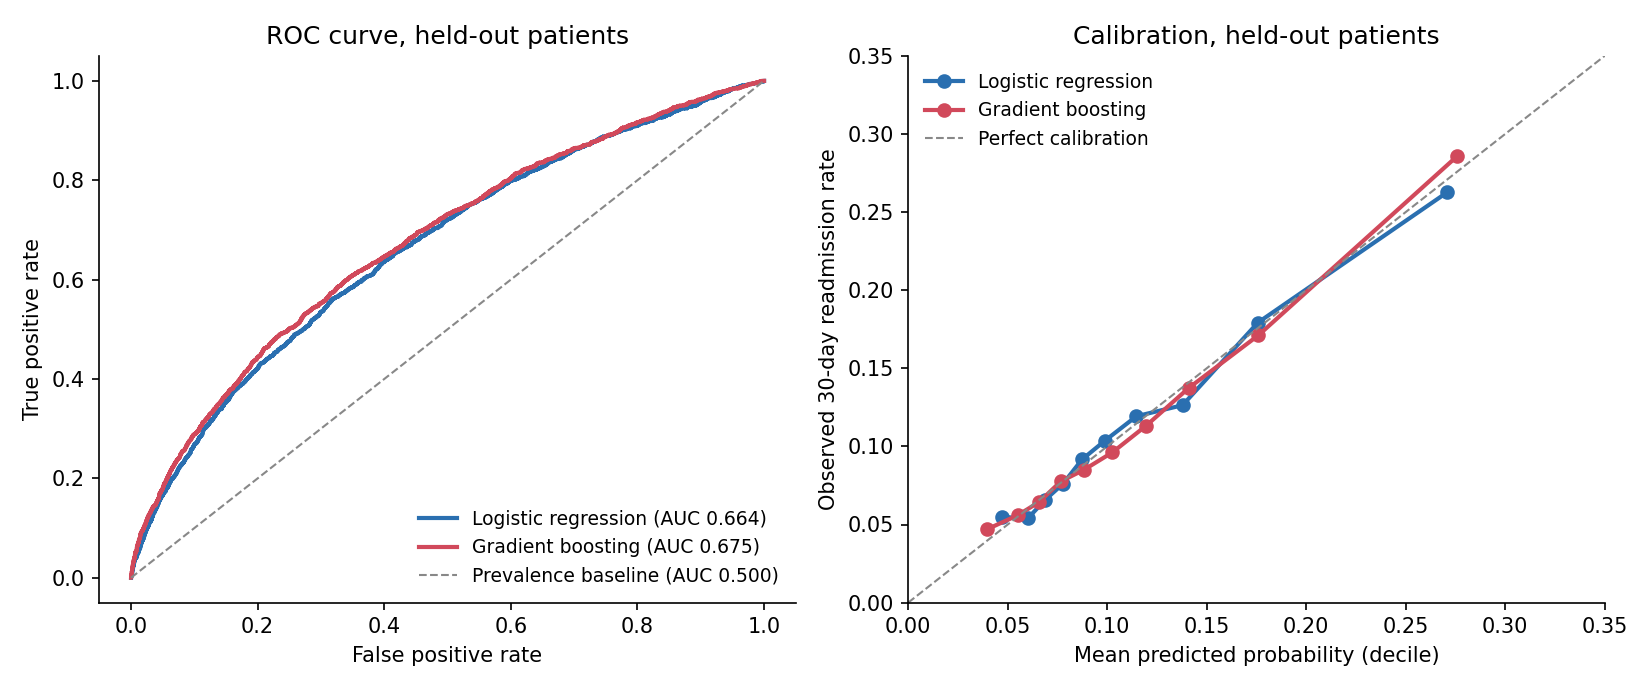

,intercept,slope
logistic_regression,-0.059,0.972
gradient_boosting,0.001,1.004


In [4]:
display(Image("figures/roc_calibration.png"))
pd.DataFrame(summary["calibration_intercept_slope"]).T

## Operating points

A care-management team can only call so many patients. The score cutoff for each flag rate is set on the validation patients and applied unchanged to the test patients.

In [5]:
pd.read_csv("metrics/threshold_metrics.csv")

,target_flag_rate,score_cutoff,test_flag_rate,precision,recall,lift_over_prevalence
0,0.05,0.243,0.054,0.325,0.155,2.863
1,0.10,0.198,0.105,0.280,0.258,2.466
2,0.20,0.154,0.203,0.228,0.408,2.009
3,0.30,0.129,0.301,0.198,0.526,1.750


## Decision curve: is acting on the score worth it?

Net benefit (Vickers and Elkin, 2006) counts readmissions reached per patient, minus unneeded interventions weighted by the odds at the chosen risk threshold. A threshold of 20% means a team accepts up to four unneeded calls for each readmission it reaches. The model is compared with intervening on everyone and on no one.

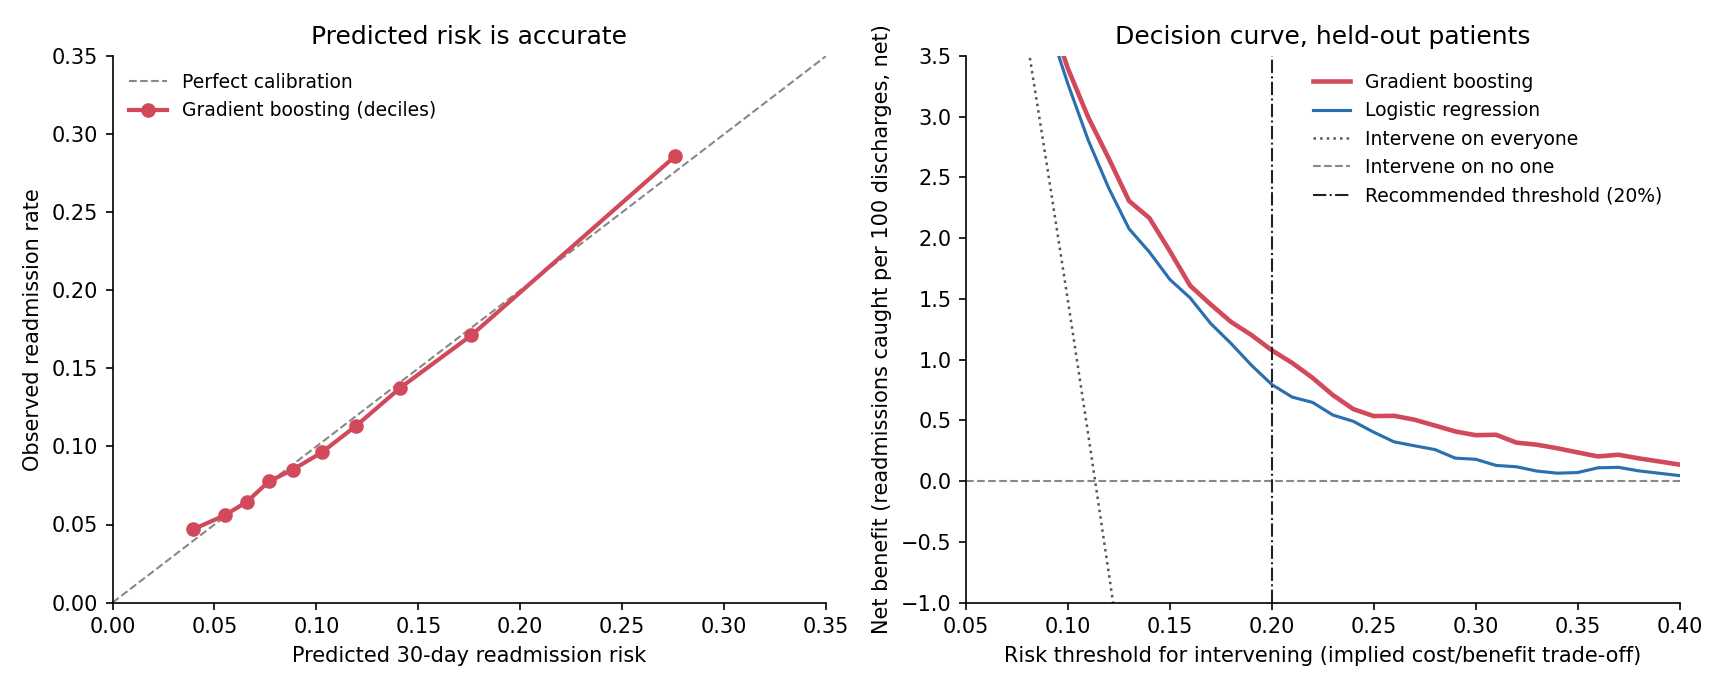

,gradient_boosting,logistic_regression,treat_all,gain_95ci
0.1,0.034,0.033,0.015,0.0161 to 0.0220
0.15,0.019,0.017,-0.043,0.0149 to 0.0239
0.2,0.011,0.008,-0.108,0.0076 to 0.0146
0.25,0.005,0.004,-0.182,0.0027 to 0.0083
0.3,0.004,0.002,-0.267,0.0017 to 0.0063


In [6]:
display(Image("figures/decision_curve.png"))
da = summary["decision_analysis"]
pd.DataFrame(da["net_benefit_at"]).T.assign(
    gain_95ci=[f"{v['low_2.5']:.4f} to {v['high_97.5']:.4f}" for v in da["bootstrap_95pct"]["net_benefit_gain"].values()]
)

## Subgroup diagnostics

Discrimination and calibration-in-the-large (observed rate vs. mean predicted risk) by gender, race and age band, for groups with at least 200 test encounters.

In [7]:
pd.read_csv("metrics/subgroup_metrics.csv")

,feature,group,n,observed_rate,mean_predicted,roc_auc,pr_auc
0,gender,Female,10804,0.113,0.116,0.680,0.238
1,gender,Male,9057,0.114,0.112,0.669,0.234
2,race,AfricanAmerican,3927,0.116,0.120,0.671,0.251
3,race,Caucasian,14670,0.115,0.114,0.673,0.234
4,race,Hispanic,396,0.076,0.100,0.782,0.180
5,race,Missing,449,0.098,0.076,0.667,0.207
6,race,Other,286,0.087,0.106,0.704,0.256
7,age,[20-30),369,0.171,0.158,0.782,0.434
8,age,[30-40),764,0.101,0.115,0.712,0.223
9,age,[40-50),1873,0.104,0.104,0.707,0.274


## What drives the predictions

Permutation importance on the validation patients (how much ROC-AUC drops when one input column is shuffled) and partial dependence for the two strongest inputs. These are predictive associations, not causal effects: a discharge to a rehab facility marks sicker patients, it doesn't cause readmission.

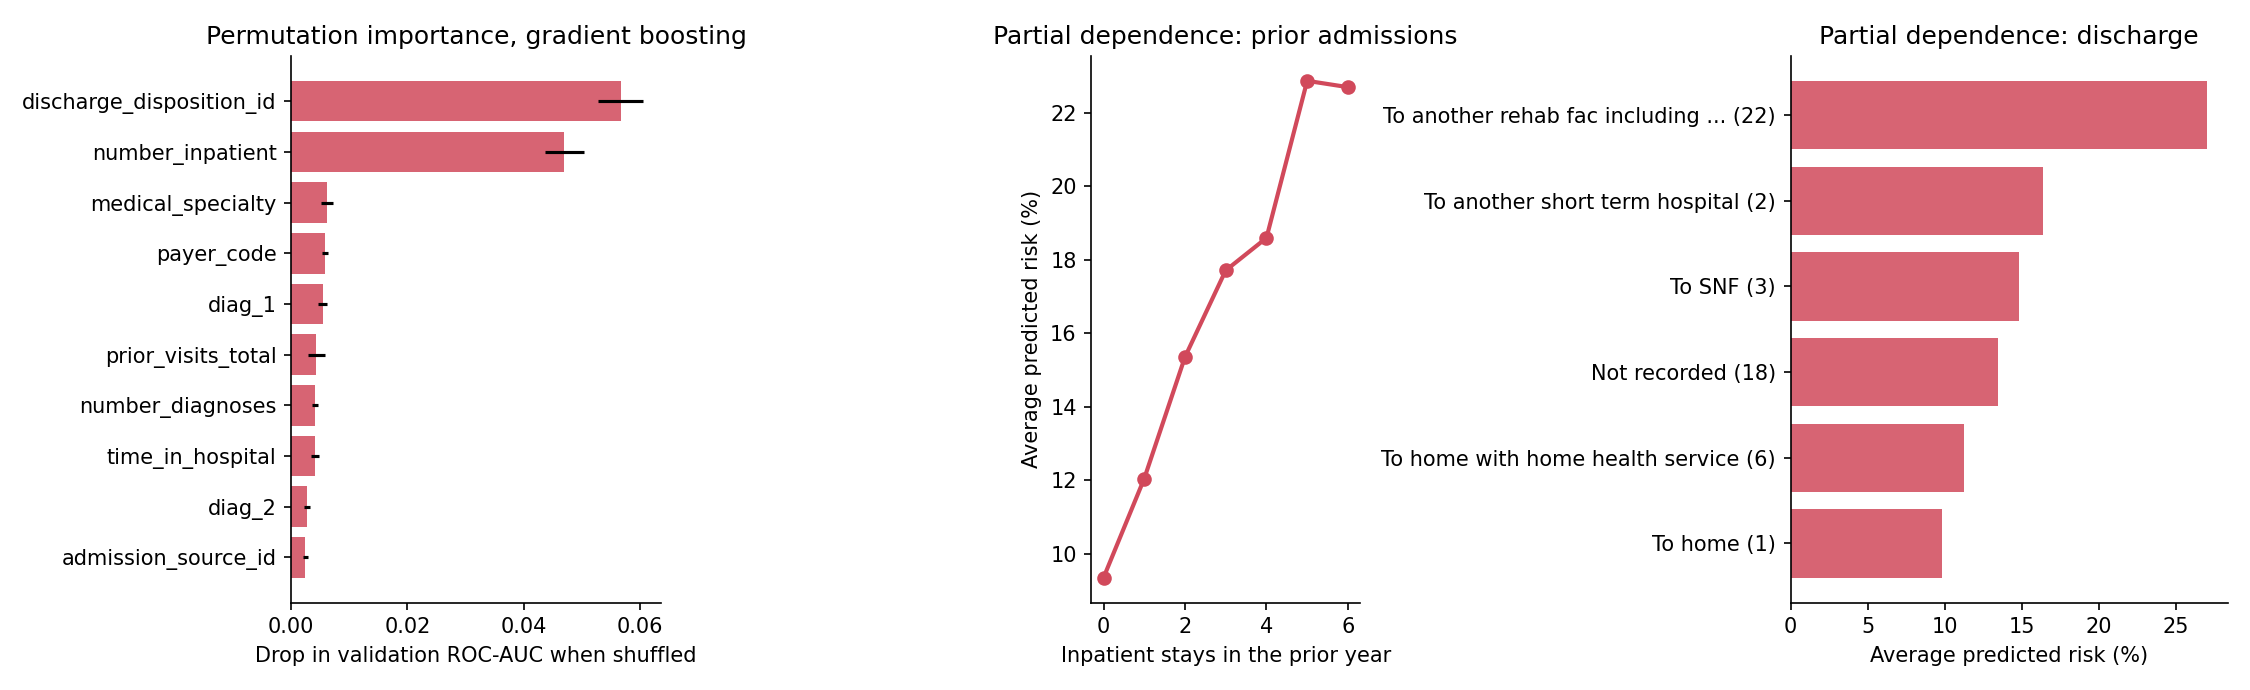

,feature,value,mean_predicted_risk,label
0,number_inpatient,0.0,0.093,NaN
1,number_inpatient,1.0,0.120,NaN
2,number_inpatient,2.0,0.154,NaN
3,number_inpatient,3.0,0.177,NaN
4,number_inpatient,4.0,0.186,NaN
5,number_inpatient,5.0,0.229,NaN
6,number_inpatient,6.0,0.227,NaN
7,discharge_disposition_id,1.0,0.098,To home (1)
8,discharge_disposition_id,3.0,0.148,To SNF (3)
9,discharge_disposition_id,6.0,0.113,To home with home health service (6)


In [8]:
display(Image("figures/drivers.png"))
pd.read_csv("metrics/permutation_importance.csv").head(10)
pd.read_csv("metrics/partial_dependence.csv")

## Takeaways

* Prior inpatient use and discharge destination carry most of the signal.
* Gradient boosting beats logistic regression by a small but consistent margin, and its predicted risks are well calibrated on held-out patients.
* Acting on the score beats calling everyone or no one at every risk threshold from 5% to 40%. A 20% threshold flags about one discharge in ten, of whom 28% are readmitted.